In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
dataset = pd.read_csv('Ads_CTR_Optimisation.csv')
print(dataset.describe())

import random
N = 10000
d = 10

epsilon = 0.1

numbers_of_selections = [0] * d
sums_of_rewards = [0] * d
ads_selected = []
total_reward = 0

               Ad 0          Ad 1          Ad 2          Ad 3          Ad 4  \
count  10000.000000  10000.000000  10000.000000  10000.000000  10000.000000   
mean       0.170300      0.129500      0.072800      0.119600      0.269500   
std        0.375915      0.335769      0.259821      0.324509      0.443722   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.000000      0.000000      0.000000      0.000000      0.000000   
50%        0.000000      0.000000      0.000000      0.000000      0.000000   
75%        0.000000      0.000000      0.000000      0.000000      1.000000   
max        1.000000      1.000000      1.000000      1.000000      1.000000   

               Ad 5          Ad 6          Ad 7          Ad 8         Ad 9  
count  10000.000000  10000.000000  10000.000000  10000.000000  10000.00000  
mean       0.012600      0.111200      0.209100      0.095200      0.04890  
std        0.111546      0.314395      0.406686      0.29

Total reward: 2524
The best ad (index) is: 4
The best ad (number of times selected) is: 8862


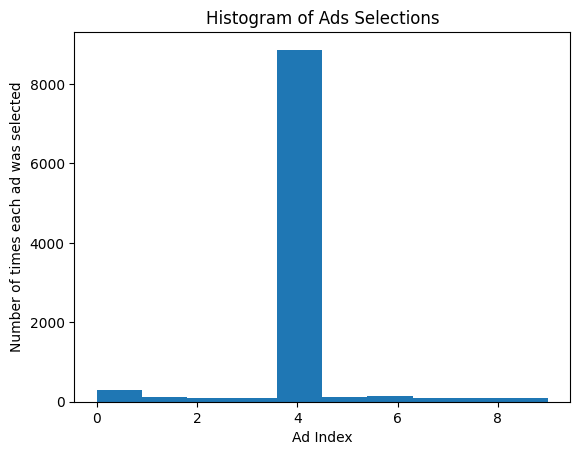

In [3]:
for n in range(N):
    ad = 0
    if random.uniform(0, 1) < epsilon:
        ad = random.randrange(d)
    else:
        max_upper_bound = 0
        for i in range(d):
            if numbers_of_selections[i] > 0:
                average_reward = sums_of_rewards[i] / numbers_of_selections[i]
                if average_reward > max_upper_bound:
                    max_upper_bound = average_reward
                    ad = i
            else:
                ad = i
                break

    ads_selected.append(ad)
    numbers_of_selections[ad] += 1
    reward = dataset.values[n, ad]
    sums_of_rewards[ad] += reward
    total_reward += reward

winning_ad_index = np.argmax(sums_of_rewards)

print(f"Total reward: {total_reward}")
print(f"The best ad (index) is: {winning_ad_index}")
print(f"The best ad (number of times selected) is: {numbers_of_selections[winning_ad_index]}")

plt.hist(ads_selected)
plt.title('Histogram of Ads Selections')
plt.xlabel('Ad Index')
plt.ylabel('Number of times each ad was selected')
plt.show()